In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
import warnings 
warnings.filterwarnings("ignore")

In [2]:
cd C:\Users\hp\OneDrive\Documents

C:\Users\hp\OneDrive\Documents


In [3]:
data=pd.read_csv("bank1")

In [4]:
data.drop("Unnamed: 0",axis=1)

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1.0,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1.0,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0.0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0.0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,771,France,Male,39,5,0.00,2,1,0.0,96270.64,0
9996,15569892,516,India,Male,35,10,57369.61,1,1,0.0,101699.77,0
9997,15584532,709,France,Male,36,7,0.00,1,0,1.0,42085.58,1
9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0.0,92888.52,1


##Q1. Load the cleaned Bank Customer dataset. Identify the Type of
##ML Problem.
##Select 'Churn' as target variable, and print the shape of X and y

In [5]:
x=data.drop("churn",axis=True)
y=data["churn"]       

In [6]:
data

,Unnamed: 0,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,0,15634602,619,France,Female,42,2,0.00,1,1,1.0,101348.88,1
1,1,15647311,608,Spain,Female,41,1,83807.86,1,0,1.0,112542.58,0
2,2,15619304,502,France,Female,42,8,159660.80,3,1,0.0,113931.57,1
3,3,15701354,699,France,Female,39,1,0.00,2,0,0.0,93826.63,0
4,4,15737888,850,Spain,Female,43,2,125510.82,1,1,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,15606229,771,France,Male,39,5,0.00,2,1,0.0,96270.64,0
9996,9996,15569892,516,India,Male,35,10,57369.61,1,1,0.0,101699.77,0
9997,9997,15584532,709,France,Male,36,7,0.00,1,0,1.0,42085.58,1
9998,9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0.0,92888.52,1


In [7]:
x.shape

(10000, 12)

In [8]:
y.shape

(10000,)

##Q2. Identify categorical columns, apply Encoding techniques (if
##necessary, perform Standard Scaling on numerical features. 

In [9]:
from sklearn.preprocessing import LabelEncoder

In [10]:
label=LabelEncoder()

In [11]:
x=x.apply(label.fit_transform)

In [21]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,random_state=42)

In [12]:
from sklearn.preprocessing import StandardScaler

In [13]:
scale=StandardScaler()

In [16]:
X= scale.fit_transform(x)

In [17]:
from sklearn.model_selection import train_test_split

In [22]:
x_train=pd.DataFrame(scale.fit_transform(x_train),columns=x.columns)

In [23]:
x_test=pd.DataFrame(scale.transform(x_test),columns=x.columns)

##Q.3.Plot churn distribution. Analyze the relationship between
##CreditScore, Age, and Balance with churn

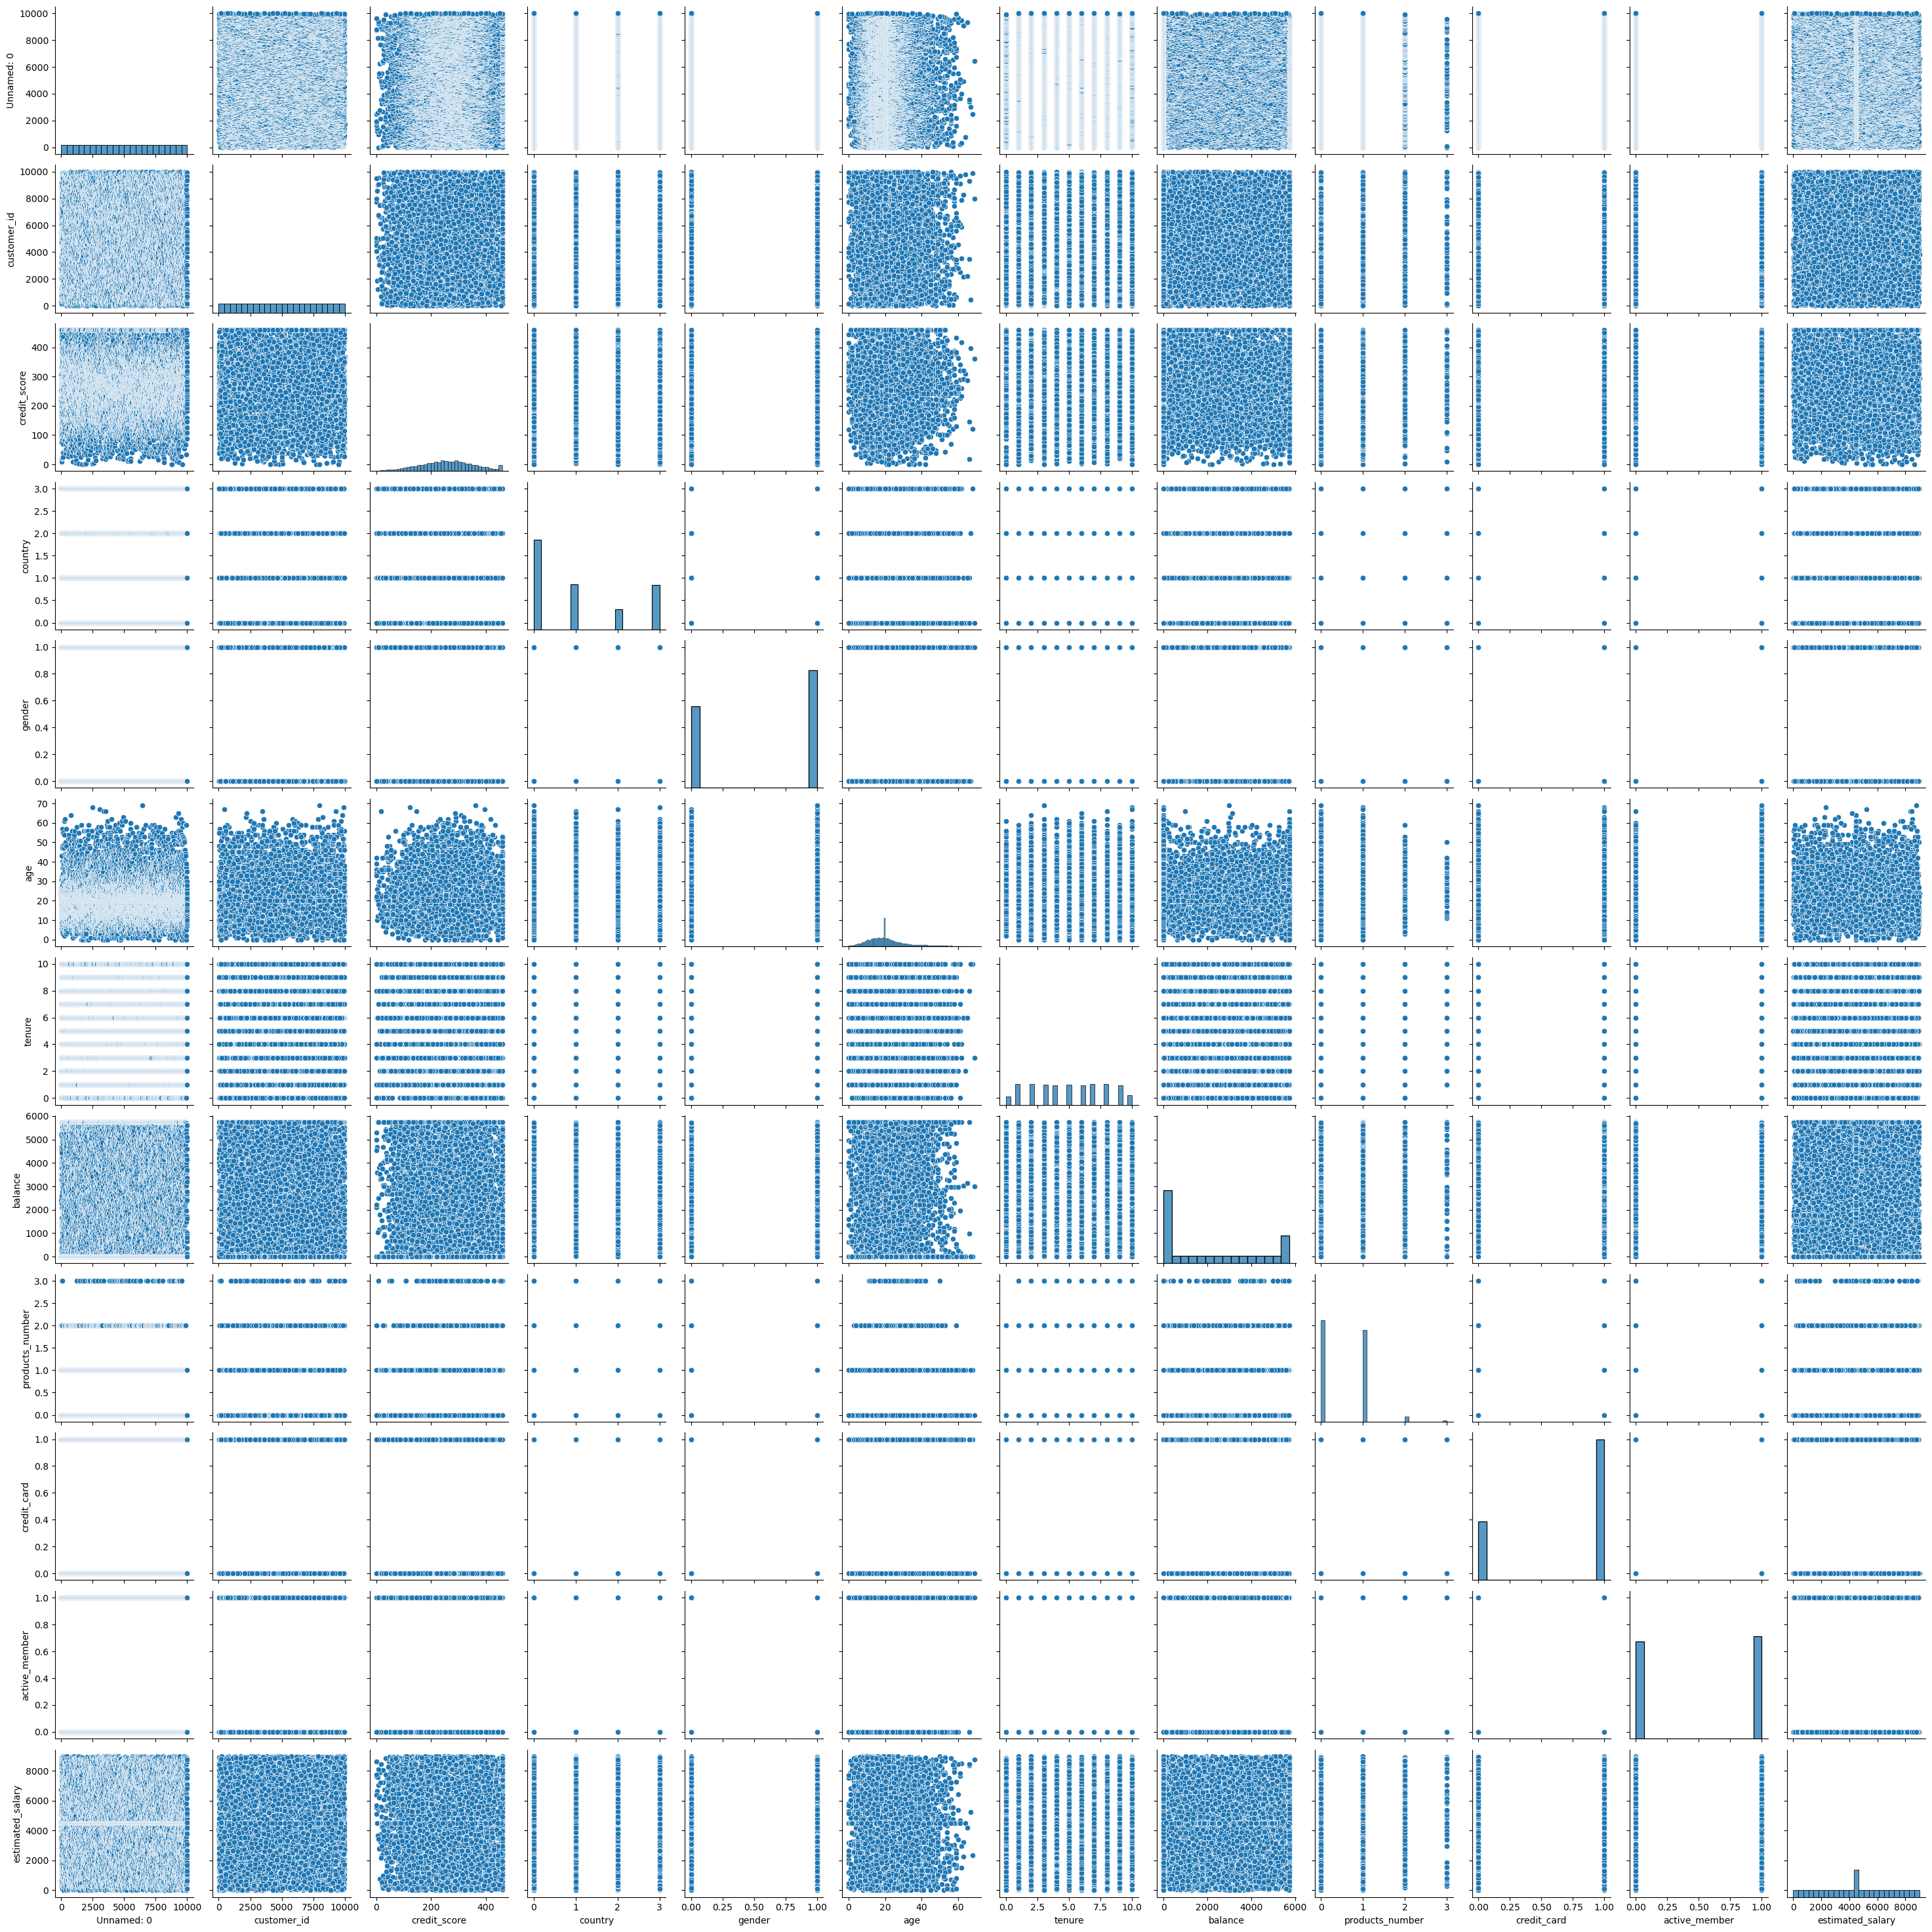

In [24]:
sns.pairplot(x)

##Q.4 Split the dataset into training and testing sets. Train a SVM model
##and display accuracy Score, Confusion Matrix, Classification
##Report..
 

In [25]:
from sklearn.svm import SVC

In [26]:
model=SVC()

In [27]:
model.fit(x_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [28]:
model.score(x_train,y_train)*100

85.54285714285714

In [29]:
model.score(x_test,y_test)*100

85.46666666666667

In [30]:
pri=model.predict(x_test)

In [31]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [32]:
accuracy_score(y_test,pri)*100

85.46666666666667

In [33]:
a=confusion_matrix(y_test,pri)

<Axes: >

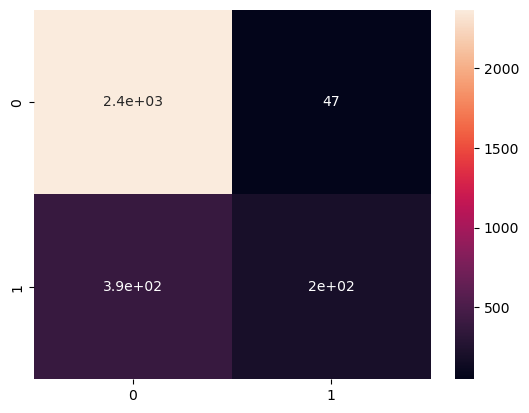

In [34]:
sns.heatmap(a,annot=True)

In [35]:
print(classification_report(y_test,pri))

              precision    recall  f1-score   support

           0       0.86      0.98      0.92      2416
           1       0.81      0.33      0.47       584

    accuracy                           0.85      3000
   macro avg       0.83      0.66      0.69      3000
weighted avg       0.85      0.85      0.83      3000



##Q5. Train a Random Forest Classifier on the same data and predict
##Churn,find - accuracy Score, Confusion Matrix, Classification
##Report.

In [36]:
from sklearn.ensemble import RandomForestClassifier

In [37]:
model1=RandomForestClassifier()

In [38]:
x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=100)

In [39]:
model1.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [40]:
model1.score(x_train,y_train)*100

100.0

In [41]:
model1.score(x_test,y_test)*100

85.0

In [42]:
pri1=model1.predict(x_test)

In [43]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [44]:
accuracy_score(y_test,pri1)*100

85.0

In [45]:
b=confusion_matrix(y_test,pri1)

<Axes: >

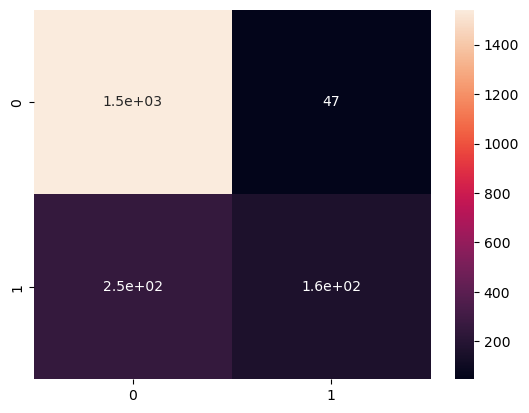

In [46]:
sns.heatmap(b,annot=True)

In [47]:
print(classification_report(y_test,pri1))

              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1588
           1       0.77      0.39      0.51       412

    accuracy                           0.85      2000
   macro avg       0.82      0.68      0.71      2000
weighted avg       0.84      0.85      0.83      2000



In [48]:
model1

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [49]:
import  pickle

In [50]:
pickle.dump(model,open('churn.pkl','wb'))

In [51]:
pwd

'C:\\Users\\hp\\OneDrive\\Documents'